# Module 8 · Renewal processes, continuous-time chains, and birth–death models
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **When do counts hide the waiting time or the time spent without a bike?**

Guided work: about 45–55 minutes. Exercises: about 25–35 minutes. This is **Concept Lab 4, Part B (week 8)**. Combine it with Module 7, Part A, as **one lab submission due in week 8**. Continue the existing course project.

[Course home](../index.html) · [Interactive lesson](../modules/module08.html) · [Project guide](../project-guide.html)

We first replace exponential interarrival times with general renewal gaps. Then we model a **synthetic** finite bike station whose inventory changes continuously in time. Finally, we audit what the real daily system totals can support. Every event time, inventory path, capacity, and station rate below is synthetic.

## 1. Generalize the Poisson clock
Let $W_1,W_2,\ldots$ be iid **positive** gap lengths, $S_0=0$, and $S_n=\sum_{j=1}^n W_j$. An ordinary renewal process starts a fresh cycle at time zero and counts only later renewals:

$$N(t)=\max\{n:S_n\le t\},\qquad N(0)=0.$$

The renewal at zero is the starting convention, not an event added to $N(t)$. We compare three laws with the **same mean gap of one hour**: exponential(rate 1), Erlang(shape 2, rate 2), and deterministic $W=1$. Their gap variances are 1, 1/2, and 0 hours squared. The Erlang gap is the sum of two independent exponential(rate 2) stages. NumPy's gamma/exponential argument is **scale**, the reciprocal of rate.

For iid positive gaps with finite mean $\mu$, $N(t)/t\to1/\mu$ almost surely as $t\to\infty$. This is a long-run statement, not a claim that $E[N(t)]=t/\mu$ at every finite time. General renewal counts usually lack the Poisson process's independent increments; age since the last renewal carries information.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.linalg import expm
from scipy.stats import poisson
from IPython.display import display
SEED, REPLICAS = 6231, 2000
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

In [2]:
LAWS = ["Exponential", "Erlang-2", "Fixed"]

def draw_gap(law, rng, size=None):
    if law == "Exponential":
        return rng.exponential(1.0, size)
    if law == "Erlang-2":
        return rng.gamma(shape=2.0, scale=0.5, size=size)
    if law == "Fixed":
        return np.ones(size) if size is not None else 1.0
    raise ValueError("Choose Exponential, Erlang-2, or Fixed")

In [3]:
def renewal_paths(law, horizon, replicas=REPLICAS, seed=SEED):
    if not np.isfinite(horizon) or horizon <= 0 or int(replicas) != replicas or replicas < 1:
        raise ValueError("Use a positive finite horizon and positive integer replicas")
    rng, paths = np.random.default_rng(seed), []
    for _ in range(replicas):
        time, events = 0.0, []
        while True:
            time += draw_gap(law, rng)
            if time > horizon:
                break
            events.append(time)
        paths.append(np.asarray(events))
    return paths

In [4]:
def renewal_moments(law, t):
    if law == "Exponential":
        return t, t
    if law == "Erlang-2":
        return t-(1-np.exp(-4*t))/4, t/2+(1-np.exp(-8*t))/16-t*np.exp(-4*t)
    return np.floor(t), 0.0

def survival(law, t):
    t = np.asarray(t)
    if law == "Exponential":
        return np.exp(-t)
    if law == "Erlang-2":
        return np.exp(-2*t)*(1+2*t)
    return (t < 1).astype(float)

### An exact benchmark at finite time
With exponential gaps, $N(T)\sim\mathrm{Poisson}(T)$. With fixed gaps, $N(T)=\lfloor T\rfloor$, including a renewal exactly at $T$. For Erlang-2 gaps, pair consecutive events of a rate-2 Poisson process. If $M(T)\sim\mathrm{Poisson}(2T)$, then $N(T)=\lfloor M(T)/2\rfloor$, so

$$P(N(T)=n)=P(M(T)=2n)+P(M(T)=2n+1),$$
$$E[N(T)]=T-\frac{1-e^{-4T}}4,\qquad
\operatorname{Var}N(T)=\frac T2+\frac{1-e^{-8T}}{16}-Te^{-4T}.$$

At the displayed horizons, the count mean is about $T-0.25$, despite a mean gap of exactly one hour. The simulator draws gaps until the first event beyond the horizon; that last gap is **right censored by observation**. It does not add the horizon as an arrival. Extending a horizontal plotting segment to $T$ adds no event.

In [5]:
RENEWAL_HORIZON = 8.0
renewal_runs, renewal_rows = {}, []
for j, law in enumerate(LAWS):
    paths = renewal_paths(law, RENEWAL_HORIZON, seed=SEED+j)
    counts = np.array([len(path) for path in paths])
    exact_mean, exact_var = renewal_moments(law, RENEWAL_HORIZON)
    renewal_runs[law] = (paths, counts)
    renewal_rows.append([law, exact_mean, counts.mean(), exact_var, counts.var(ddof=1),
                         counts.std(ddof=1)/np.sqrt(REPLICAS)])
    assert abs(counts.mean()-exact_mean) <= 6*np.sqrt(exact_var/REPLICAS)+1e-12
    assert all(np.all(np.diff(path) > 0) and np.all((path > 0) & (path <= RENEWAL_HORIZON)) for path in paths)
renewal_table = pd.DataFrame(renewal_rows, columns=["Gap law", "Exact count mean", "MC mean",
    "Exact count variance", "MC variance", "Mean MCSE"]).set_index("Gap law")
display(renewal_table.round(5))

,Exact count mean,MC mean,Exact count variance,MC variance,Mean MCSE
Gap law,,,,,
Exponential,8.00,7.9645,8.0000,7.96022,0.06309
Erlang-2,7.75,7.7360,4.0625,4.16038,0.04561
Fixed,8.00,8.0000,0.0000,0.00000,0.00000


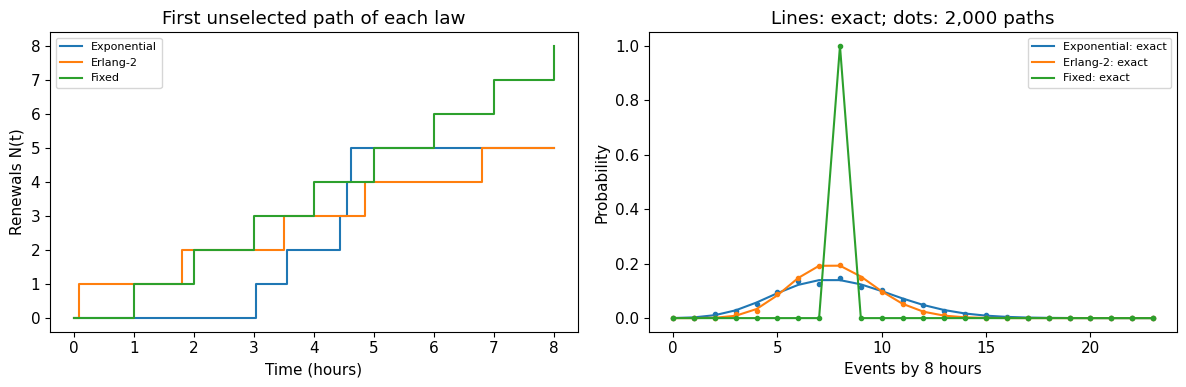

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k = np.arange(max(23, int(2*RENEWAL_HORIZON+8)))
for law, (paths, counts) in renewal_runs.items():
    events = paths[0]
    axes[0].step(np.r_[0, events, RENEWAL_HORIZON], np.r_[0, np.arange(1, len(events)+1), len(events)], where="post", label=law)
    empirical = np.array([(counts == n).mean() for n in k])
    exact = poisson.pmf(k, RENEWAL_HORIZON) if law == "Exponential" else (poisson.pmf(2*k, 2*RENEWAL_HORIZON)+poisson.pmf(2*k+1, 2*RENEWAL_HORIZON))
    if law == "Fixed":
        exact = (k == np.floor(RENEWAL_HORIZON)).astype(float)
    line, = axes[1].plot(k, exact, label=f"{law}: exact")
    axes[1].plot(k, empirical, "o", ms=3, color=line.get_color())
axes[0].set(xlabel="Time (hours)", ylabel="Renewals N(t)", title="First unselected path of each law"); axes[0].legend(fontsize=8)
axes[1].set(xlabel=f"Events by {RENEWAL_HORIZON:g} hours", ylabel="Probability", title="Lines: exact; dots: 2,000 paths"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 2. Surviving a gap changes the remaining wait
For a fresh gap $W$ with survival $\overline F(w)=P(W>w)$, condition on no renewal during its first $a$ hours:

$$P(W-a>h\mid W>a)=\frac{\overline F(a+h)}{\overline F(a)},\qquad \overline F(a)>0.$$

Only the exponential case removes the age $a$ from this expression. For Erlang-2, $\overline F(w)=e^{-2w}(1+2w)$; for fixed-one-hour gaps it is $1\{w<1\}$. The strict inequality matters: a fixed gap ends at hour 1, so at age 0.5 the probability of waiting **more than** another 0.5 hour is zero.

These are conditionally surviving **fresh iid gaps**, not a sample of intervals selected by observing a process at arbitrary times. Such sampling can favor longer intervals (the inspection paradox). Completed gaps collected only before a fixed deadline instead exclude long unfinished waits. The independent direct draws below avoid that selection problem.

In [7]:
AGE, EXTRA_WAIT, GAP_DRAWS = 0.5, 0.5, 20000
residual_rows, complete_gaps = [], {}
for j, law in enumerate(LAWS):
    waits = draw_gap(law, np.random.default_rng(SEED+10+j), GAP_DRAWS)
    eligible = waits[waits > AGE]
    estimate = np.mean(eligible > AGE+EXTRA_WAIT)
    exact = survival(law, AGE+EXTRA_WAIT)/survival(law, AGE)
    mcse = np.sqrt(estimate*(1-estimate)/len(eligible))
    complete_gaps[law] = waits
    residual_rows.append([law, len(eligible), float(exact), estimate, mcse])
display(pd.DataFrame(residual_rows, columns=["Gap law", "Survivors at age .5",
    "Exact P(extra wait > .5)", "MC probability", "Conditional MCSE"]).set_index("Gap law").round(5))
assert np.isclose(survival("Erlang-2", 1)/survival("Erlang-2", .5), 1.5/np.e)

,Survivors at age .5,Exact P(extra wait > .5),MC probability,Conditional MCSE
Gap law,,,,
Exponential,12053,0.60653,0.60483,0.00445
Erlang-2,14663,0.55182,0.55425,0.00410
Fixed,20000,0.00000,0.00000,0.00000


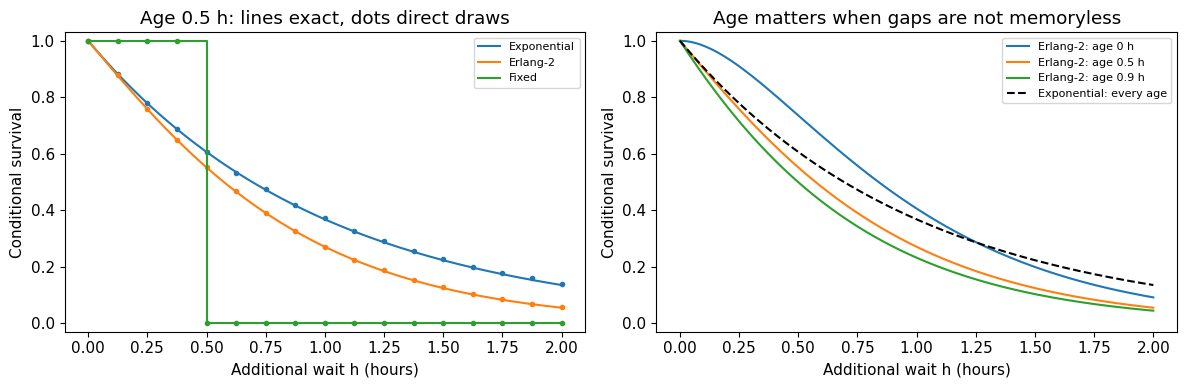

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
h = np.linspace(0, 2, 161)
for law in LAWS:
    exact = survival(law, AGE+h)/survival(law, AGE)
    line, = axes[0].plot(h, exact, label=law, drawstyle="steps-post" if law == "Fixed" else "default")
    eligible = complete_gaps[law][complete_gaps[law] > AGE]-AGE
    axes[0].plot(h[::10], (eligible[:, None] > h[::10]).mean(axis=0), "o", color=line.get_color(), ms=3)
for age in [0, .5, .9]:
    axes[1].plot(h, survival("Erlang-2", age+h)/survival("Erlang-2", age), label=f"Erlang-2: age {age} h")
axes[1].plot(h, np.exp(-h), color="black", ls="--", label="Exponential: every age")
axes[0].set(xlabel="Additional wait h (hours)", ylabel="Conditional survival", title="Age 0.5 h: lines exact, dots direct draws")
axes[1].set(xlabel="Additional wait h (hours)", ylabel="Conditional survival", title="Age matters when gaps are not memoryless")
for ax in axes:
    ax.legend(fontsize=8); ax.set_ylim(-.03, 1.03)
fig.tight_layout(); plt.show()

The probability MCSE uses the number of surviving independent gap draws, not all 20,000 draws. At different ages or thresholds we reuse samples, so the plotted estimates are correlated. A zero MCSE for the fixed law reflects deterministic behavior under this model, not certainty that actual bike events have fixed gaps. Count-mean MCSE is sample SD across independent paths divided by $\sqrt R$; it is not the uncertainty of a sample variance or a prediction interval.

## 3. Inventory is a state, not a cumulative count
Consider a **synthetic single station** with capacity $K=4$ and inventory $X(t)\in\{0,1,2,3,4\}$, starting at $X(0)=2$. Independent exogenous Poisson return attempts arrive at $\alpha=2$/hour, and rental attempts at $\beta=3$/hour. A successful return increases inventory by one; a successful rental decreases it by one. Returns at a full station and rentals at an empty station are blocked. These numerical choices are teaching scenarios, not fits to the UCI system totals.

Let $b_i=\alpha 1\{i<K\}$ and $d_i=\beta1\{i>0\}$. The **row generator** satisfies

$$q_{i,i+1}=b_i,\quad q_{i,i-1}=d_i,\quad q_{ii}=-(b_i+d_i),\qquad Q\mathbf1=0.$$

Off-diagonal entries are transition rates per hour, not probabilities. The holding time before a **state change** is exponential with rate $b_i+d_i$. At an interior state the next jump is upward with probability $b_i/(b_i+d_i)$. At zero the exit rate is only $\alpha$; at capacity it is only $\beta$. Blocked attempts leave the state unchanged and are excluded from its exit rate. A simulator may track all attempts explicitly, but it must distinguish self-events from state changes.

In [9]:
def station_generator(capacity=4, returns=2.0, rentals=3.0):
    if int(capacity) != capacity or capacity < 1:
        raise ValueError("Capacity must be a positive integer")
    if not np.all(np.isfinite([returns, rentals])) or min(returns, rentals) <= 0:
        raise ValueError("This irreducible station example requires positive finite rates")
    q = np.zeros((capacity+1, capacity+1))
    for i in range(capacity+1):
        if i < capacity:
            q[i, i+1] = returns
        if i > 0:
            q[i, i-1] = rentals
    q[np.diag_indices_from(q)] = -q.sum(axis=1)
    return q

In [10]:
def station_path(q, horizon, initial, rng):
    time, state = 0.0, initial
    times, states, dwell = [0.0], [initial], np.zeros(len(q))
    while time < horizon:
        rate = -q[state, state]
        wait = rng.exponential(1/rate) if rate > 0 else np.inf
        dwell[state] += min(wait, horizon-time)
        if time+wait > horizon:
            break
        time += wait
        probabilities = q[state].copy()
        probabilities[state] = 0
        state = int(rng.choice(len(q), p=probabilities/rate))
        times.append(time); states.append(state)
    return np.array(times), np.array(states), dwell

In [11]:
def stationary(capacity, returns, rentals):
    weights = (returns/rentals)**np.arange(capacity+1)
    return weights/weights.sum()

def expected_occupation(q, horizon, initial):
    size = len(q)
    augmented = np.block([[q, np.eye(size)], [np.zeros((size, 2*size))]])
    integrated = expm(augmented*horizon)[:size, size:]
    return integrated[initial]/horizon

In [12]:
def station_replicas(q, horizon, initial, replicas=REPLICAS, seed=SEED+1):
    if not np.isfinite(horizon) or horizon <= 0 or int(replicas) != replicas or replicas < 1:
        raise ValueError("Use a positive horizon and positive integer replicas")
    if int(initial) != initial or not 0 <= initial < len(q):
        raise ValueError("Initial state must be a valid integer state")
    rng = np.random.default_rng(seed)
    paths = [station_path(q, horizon, initial, rng) for _ in range(replicas)]
    occupation = np.array([path[2]/horizon for path in paths])
    final = np.array([path[1][-1] for path in paths])
    return paths, occupation, final

### Transition probabilities and occupation are different objects
For a finite time-homogeneous chain,

$$P(t)=e^{Qt},\qquad p(t)=p(0)P(t),\qquad p'(t)=p(t)Q.$$

An inventory path is simulated exactly by successive holds and jumps, with no small time step. The final hold contributes only the duration before $T$; its unobserved remainder is censored. A plot may extend the last state to $T$, but no fictitious jump is inserted there.

For an irreducible finite birth–death chain, local balance gives $\pi_i b_i=\pi_{i+1}d_{i+1}$. Thus this station has $\pi_i\propto(\alpha/\beta)^i$, normalized over $0,\ldots,K$; equal rates give a uniform distribution. For the default scenario,

$$\pi=\frac1{211}(81,54,36,24,16),\qquad \pi Q=0.$$

A path's time fraction in state $i$ is $\widehat O_i(T)=T^{-1}\int_0^T1\{X(t)=i\}\,dt$. Its finite-horizon expectation is $T^{-1}\int_0^T p_i(t)\,dt$, generally different from both $p_i(T)$ and $\pi_i$. The block matrix exponential in `expected_occupation` computes that integral without trying to invert the singular generator.

In [13]:
CAPACITY, RETURNS, RENTALS, CTMC_HORIZON = 4, 2.0, 3.0, 24.0
INITIAL = CAPACITY//2
Q = station_generator(CAPACITY, RETURNS, RENTALS)
pi = stationary(CAPACITY, RETURNS, RENTALS)
paths, occupation, final_states = station_replicas(Q, CTMC_HORIZON, INITIAL)
finite_occupation = expected_occupation(Q, CTMC_HORIZON, INITIAL)
occupation_mcse = occupation.std(axis=0, ddof=1)/np.sqrt(REPLICAS)
final_exact = expm(Q*CTMC_HORIZON)[INITIAL]
final_mc = np.bincount(final_states, minlength=CAPACITY+1)/REPLICAS
display(pd.DataFrame(Q, index=range(CAPACITY+1), columns=range(CAPACITY+1)))
display(pd.DataFrame({"MC time fraction": occupation.mean(axis=0), "Replica MCSE": occupation_mcse,
    "Finite exact time fraction": finite_occupation, "Stationary fraction": pi,
    "Final-time exact probability": final_exact}).rename_axis("Bikes").round(6))

,0,1,2,3,4
0,-2.0,2.0,0.0,0.0,0.0
1,3.0,-5.0,2.0,0.0,0.0
2,0.0,3.0,-5.0,2.0,0.0
3,0.0,0.0,3.0,-5.0,2.0
4,0.0,0.0,0.0,3.0,-3.0


,MC time fraction,Replica MCSE,Finite exact time fraction,Stationary fraction,Final-time exact probability
Bikes,,,,,
0,0.375520,0.002267,0.373846,0.383886,0.383886
1,0.254221,0.001250,0.254562,0.255924,0.255924
2,0.177308,0.001167,0.178595,0.170616,0.170616
3,0.116940,0.001261,0.116430,0.113744,0.113744
4,0.076011,0.001239,0.076567,0.075829,0.075829


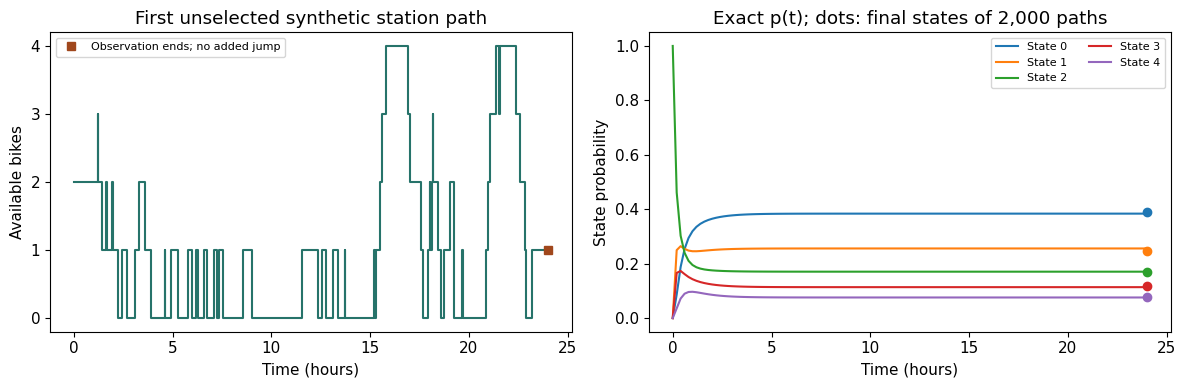

In [14]:
time_grid = np.linspace(0, CTMC_HORIZON, 121)
transient = np.array([expm(Q*t)[INITIAL] for t in time_grid])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
times, states, _ = paths[0]
axes[0].step(np.r_[times, CTMC_HORIZON], np.r_[states, states[-1]], where="post", color="#26736a")
axes[0].plot(CTMC_HORIZON, states[-1], "s", color="#a0471c", label="Observation ends; no added jump")
axes[0].set(xlabel="Time (hours)", ylabel="Available bikes", title="First unselected synthetic station path", yticks=range(CAPACITY+1))
axes[0].legend(fontsize=8)
for state in range(CAPACITY+1):
    line, = axes[1].plot(time_grid, transient[:, state], label=f"State {state}")
    axes[1].plot(CTMC_HORIZON, final_mc[state], "o", color=line.get_color())
axes[1].set(xlabel="Time (hours)", ylabel="State probability", title="Exact p(t); dots: final states of 2,000 paths")
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

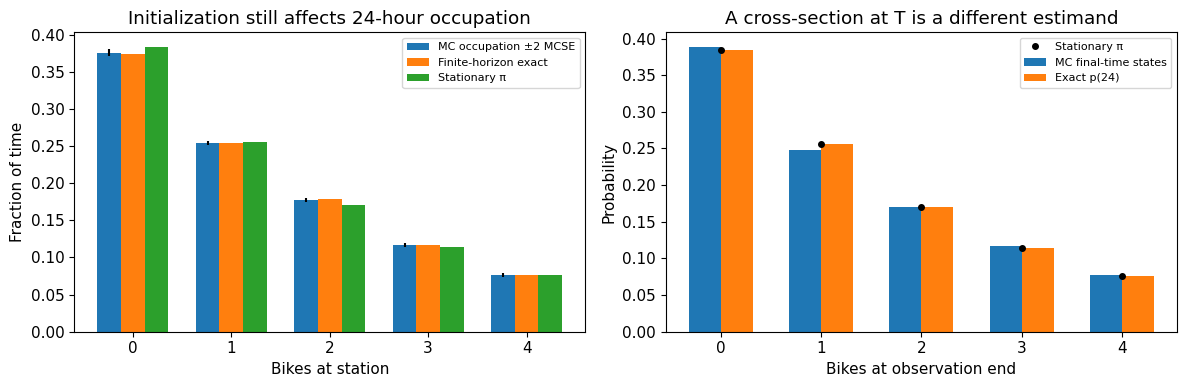

In [15]:
x = np.arange(CAPACITY+1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x-.24, occupation.mean(axis=0), .24, yerr=2*occupation_mcse, label="MC occupation ±2 MCSE")
axes[0].bar(x, finite_occupation, .24, label="Finite-horizon exact")
axes[0].bar(x+.24, pi, .24, label="Stationary π")
axes[0].set(xlabel="Bikes at station", ylabel="Fraction of time", title="Initialization still affects 24-hour occupation", xticks=x)
axes[1].bar(x-.16, final_mc, .32, label="MC final-time states")
axes[1].bar(x+.16, final_exact, .32, label="Exact p(24)")
axes[1].plot(x, pi, "ko", ms=4, label="Stationary π")
axes[1].set(xlabel="Bikes at observation end", ylabel="Probability", title="A cross-section at T is a different estimand", xticks=x)
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. Empty hours, blocked attempts, and jump visits
The completed-rental rate at stationarity is $\beta(1-\pi_0)$; the completed-return rate is $\alpha(1-\pi_K)$. They agree by flow balance. In this scenario both are $390/211\approx1.84834$ per hour. The finite-horizon expected number of blocked rental attempts is

$$E[B(T)]=\beta\,E\!\left[\int_0^T1\{X(t)=0\}\,dt\right].$$

This follows from the exogenous Poisson attempt rate. Dividing by expected total attempts $\beta T$ gives the **ratio of expectations**, equal to expected empty-time fraction. It is not generally $E[B(T)/A(T)]$; the latter needs a convention when $A(T)=0$ and is a different quantity. At stationarity the long-run blocked fraction of rental attempts is $\pi_0$ under these arrival assumptions.

Jump visits weight fast-exiting states more heavily. The stationary distribution of the embedded jump chain is $\nu_i\propto\pi_i(-q_{ii})$, not generally $\pi_i$. Recovering time occupation requires actual dwell durations (or suitable inverse-rate weighting asymptotically). The finite simulation below does not start in stationarity, so its pooled jump frequencies need not exactly equal $\nu$ either.

In [16]:
empty_hours = CTMC_HORIZON*finite_occupation[0]
completed_rentals = RENTALS*CTMC_HORIZON*(1-finite_occupation[0])
completed_returns = RETURNS*CTMC_HORIZON*(1-finite_occupation[-1])
blocked_report = pd.Series({"Exact expected empty hours": empty_hours,
    "MC mean empty hours": CTMC_HORIZON*occupation[:, 0].mean(),
    "Empty-hour MCSE": CTMC_HORIZON*occupation_mcse[0],
    "Exact expected blocked rental attempts": RENTALS*empty_hours,
    "Exact expected completed rentals": completed_rentals,
    "Stationary completed rentals/hour": RENTALS*(1-pi[0])})
display(blocked_report.round(6))
jump_visits = np.bincount(np.concatenate([p[1][1:] for p in paths]), minlength=CAPACITY+1)
jump_frequency = jump_visits/jump_visits.sum()
jump_stationary = pi*(-np.diag(Q)); jump_stationary /= jump_stationary.sum()
assert np.isclose(completed_returns-completed_rentals, final_exact@x-INITIAL)

Exact expected empty hours                 8.972305
MC mean empty hours                        9.012477
Empty-hour MCSE                            0.054414
Exact expected blocked rental attempts    26.916916
Exact expected completed rentals          45.083084
Stationary completed rentals/hour          1.848341
dtype: float64

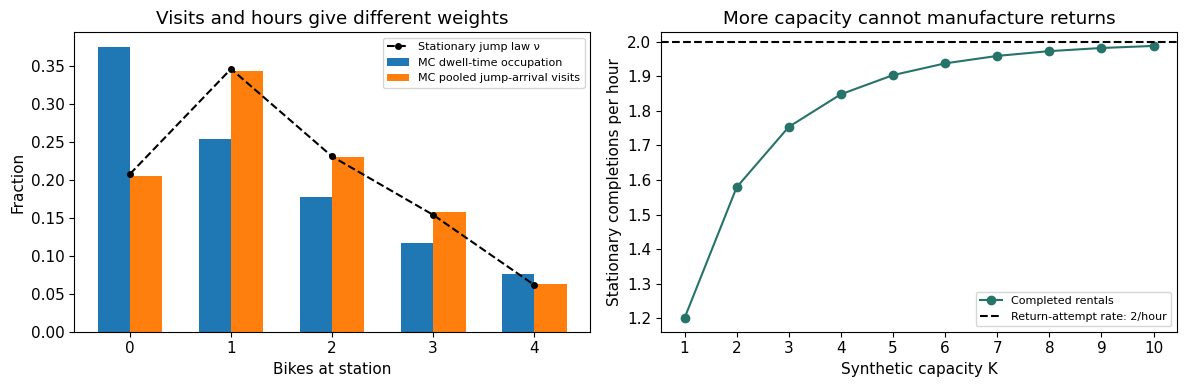

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x-.16, occupation.mean(axis=0), .32, label="MC dwell-time occupation")
axes[0].bar(x+.16, jump_frequency, .32, label="MC pooled jump-arrival visits")
axes[0].plot(x, jump_stationary, "ko--", ms=4, label="Stationary jump law ν")
axes[0].set(xlabel="Bikes at station", ylabel="Fraction", title="Visits and hours give different weights", xticks=x)
axes[0].legend(fontsize=8)
capacities = np.arange(1, 11)
throughput = [RENTALS*(1-stationary(int(k), RETURNS, RENTALS)[0]) for k in capacities]
axes[1].plot(capacities, throughput, "o-", color="#26736a", label="Completed rentals")
axes[1].axhline(RETURNS, color="black", ls="--", label="Return-attempt rate: 2/hour")
axes[1].set(xlabel="Synthetic capacity K", ylabel="Stationary completions per hour", title="More capacity cannot manufacture returns", xticks=capacities)
axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### Verify the stochastic mechanism before interpreting it
Check algebraic identities independently of random paths: generator row sums, $P(t)$ row sums/nonnegativity, the semigroup $P(s+t)=P(s)P(t)$, local balance, the finite occupation sum, and the symmetric-rate uniform case. Check paths for legal neighboring jumps, valid inventory, and exactly $T$ total observed dwell. Independent-replica MCSE quantifies numerical uncertainty in mean occupation; within one path, successive dwell rewards and state observations are dependent. More replicas do not make synthetic station assumptions empirical.

In [18]:
assert np.allclose(Q.sum(axis=1), 0) and np.all(np.diag(Q) < 0)
assert np.all(Q-np.diag(np.diag(Q)) >= 0)
assert np.allclose(expm(Q*3), expm(Q)@expm(Q*2))
assert np.allclose(expm(Q).sum(axis=1), 1) and expm(Q).min() >= -1e-12
assert np.allclose(pi@Q, 0) and np.allclose(pi[:-1]*RETURNS, pi[1:]*RENTALS)
assert np.allclose(pi, np.array([81, 54, 36, 24, 16])/211)
assert np.allclose(stationary(4, 3, 3), np.ones(5)/5)
assert np.isclose(finite_occupation.sum(), 1) and np.all(finite_occupation >= 0)
for times, states, dwell in paths:
    assert times[0] == 0 and times[-1] <= CTMC_HORIZON and np.all(np.diff(times) > 0)
    assert np.all(np.abs(np.diff(states)) == 1) and np.all((states >= 0) & (states <= CAPACITY))
    assert np.isclose(dwell.sum(), CTMC_HORIZON)
assert np.all(np.abs(occupation.mean(axis=0)-finite_occupation) < 6*occupation_mcse)
repeat = station_replicas(Q, CTMC_HORIZON, INITIAL, replicas=1)[0][0]
assert np.array_equal(paths[0][0], repeat[0]) and np.array_equal(paths[0][1], repeat[1])

## 5. What does the real bike-sharing dataset observe?
The unchanged UCI Bike Sharing 2011 sample has 365 daily **system-wide completed-rental totals** (Fanaee-T, 2013; [DOI 10.24432/C5W894](https://doi.org/10.24432/C5W894), CC BY 4.0). We preserve the established January–August / September–December boundary, but here use the later block **descriptively**, not to fit or validate a station mechanism.

The 243 January–August days contain 802,684 completed rentals: mean **3303.226337/day**. This uses full-day exposures, not adjacent-day pairs. Those totals do not identify within-day interarrival gaps, individual station inventories, capacities, returns, or rejected attempts. Dividing the daily system mean by 24 gives only an average system hourly count under an added convention; it does not identify either station rate $\alpha$ or $\beta$. A zero daily completion count would not establish empty inventory: no arrivals, closed service, data problems, or aggregation could also matter.

In [19]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/bike_daily_2011.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
csv_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT / "data/source_metadata.json").read_text())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(csv_path, parse_dates=["dteday"])
assert len(bike) == 365 and bike["dteday"].is_unique
assert bike["dteday"].tolist() == list(pd.date_range("2011-01-01", "2011-12-31"))
train = bike.loc[bike["dteday"] < "2011-09-01"].copy()
later = bike.loc[bike["dteday"] >= "2011-09-01"].copy()
assert len(train) == 243 and len(later) == 122 and train["cnt"].sum() == 802684

,Exposure days,Completed rentals,Mean completed/day,Zero-count days
Period,,,,
Jan–Aug (established training block),243,802684,3303.226337,0
Sep–Dec (descriptive later block),122,440419,3609.991803,0


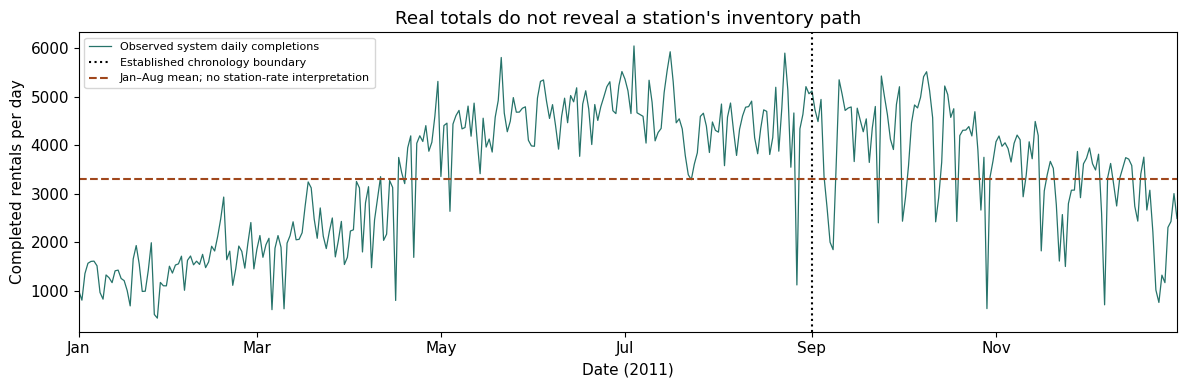

In [20]:
data_rows = []
for label, block in [("Jan–Aug (established training block)", train), ("Sep–Dec (descriptive later block)", later)]:
    data_rows.append([label, len(block), block["cnt"].sum(), block["cnt"].mean(), (block["cnt"] == 0).sum()])
data_audit = pd.DataFrame(data_rows, columns=["Period", "Exposure days", "Completed rentals",
    "Mean completed/day", "Zero-count days"]).set_index("Period")
display(data_audit.round(6))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(bike["dteday"], bike["cnt"], color="#26736a", lw=.9, label="Observed system daily completions")
ax.axvline(pd.Timestamp("2011-09-01"), color="black", ls=":", label="Established chronology boundary")
ax.axhline(train["cnt"].mean(), color="#a0471c", ls="--", label="Jan–Aug mean; no station-rate interpretation")
ax.set(xlabel="Date (2011)", ylabel="Completed rentals per day", title="Real totals do not reveal a station's inventory path")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(bike["dteday"].iloc[[0, -1]].to_list()); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

| Target quantity | Additional observations needed |
| --- | --- |
| Renewal gap law | Ordered event timestamps, observation windows, censoring, and a defensible definition of repeated iid cycles |
| Station inventory process | Station identifiers, capacity changes, initial inventory, and time-stamped inventory or successful returns/rentals |
| Return/rental attempt rates | Attempt records and exposure at each station, including blocked attempts, service outages, and calendar covariates |
| Blocked demand | Explicit unserved-attempt records or a separately justified observation model; completions alone are insufficient |

With complete state-change observation, a constant successful upward rate can be estimated from upward jumps divided by time below capacity, and a downward rate from downward jumps divided by time above zero, under the proposed CTMC assumptions. That still requires careful treatment of outages, censoring, rebalancing, and observation gaps. The present data do not supply these exposures.

Keep the project contribution small: name an event/state and its time unit, distinguish observed from synthetic quantities, specify a candidate renewal or CTMC mechanism only if the observation resolution supports it, and propose a check that could reject the model. The later daily block has already been inspected in earlier modules; it is not a new untouched test set.

## 6. Four investigations — leave your work here
Submit this notebook's exercise responses together with Module 7's responses as **one Concept Lab 4 submission, due in week 8**. Use clear units and distinguish exact model facts, Monte Carlo estimates, and claims about observed data. You may adapt the guided code; explain each important change. No extra dataset or separate project is required.

### Exercise 1 — Same mean gap, different event streams
For exponential(rate 1), Erlang-2(shape 2, rate 2), and fixed-one-hour gaps, simulate **2,000 independent ordinary renewal paths** at each of $T=8$ and $T=24$ hours. Report the count mean, sample variance, mean MCSE, and exact mean and variance. Explain why $E[N(T)]$ need not equal $T/E[W]$ at a finite horizon. Calculate $P(W>1\mid W>0.5)$ for each law; check it using **independent complete gap draws** where meaningful. Explain the deterministic boundary and why completed gaps from finite paths are a selected sample.

In [21]:
# YOUR WORK — Exercise 1
# Add your calculations, reasoning, and verification evidence here.

### Exercise 2 — Read the generator as rates
Construct $Q$ for $K=4$, return attempts $\alpha=2$/hour, rental attempts $\beta=3$/hour, and $X(0)=2$. Explain the boundary exit rates and compute the holding-time means and next-jump probabilities at states 0, 2, and 4. Double **both** attempt rates. Verify which stationary quantities stay fixed and how holding times, $P(t)$, and completed-rental throughput change. Supply generator, boundary, and horizon-conservation checks; include the equal-rate stationary case.

In [22]:
# YOUR WORK — Exercise 2
# Add your calculations, reasoning, and verification evidence here.

### Exercise 3 — Count hours, not visits
For the default station and each of $T=8$ and $T=24$ hours, simulate **2,000 independent paths** starting at 2. Compare mean dwell-time occupation with $T^{-1}\int_0^T e_2^\top e^{Qt}\,dt$ and with $\pi$; report per-state replica MCSEs. Contrast pooled jump-arrival frequencies and final-time state frequencies with occupation. Report expected empty hours and the corresponding **expected number** of blocked rental attempts, $\beta E[\text{empty hours}]$. Explain finite-horizon initialization and why the ratio of expected blocked to expected total attempts is not generally the expectation of a realized blocked fraction.

In [23]:
# YOUR WORK — Exercise 3
# Add your calculations, reasoning, and verification evidence here.

### Exercise 4 — Observation and AI audit
Use the unchanged daily bike data to report January–August and September–December exposure days, completed-rental totals, daily means, and zero-count days. Explain whether these columns identify renewal gaps, station capacity, station inventories, return rates, or blocked demand, and name the additional observations needed. Audit and repair the four flawed lines below: rate versus scale, visits versus time occupation, system totals versus station rates, and a fictitious terminal jump. Give **at least two independent checks** that would catch these errors. AI use is optional; disclose assistance and how you verified it.

```python
wait = rng.exponential(b_i + d_i)            # claimed CTMC holding time
occupation = np.bincount(visited_states) / len(visited_states)
alpha = beta = bike["cnt"].mean() / 24       # claimed station attempt rates
times.append(T); states.append(states[-1]+1) # claimed event at observation end
```

In [24]:
# YOUR WORK — Exercise 4
# Add your calculations, reasoning, and verification evidence here.

## Reproducibility and next step
Python and the browser use different random generators; paths need not match. Compare exact finite-horizon moments, generators, matrix-exponential probabilities, occupation integrals, Monte Carlo uncertainty, and unchanged data summaries. The six figures above are generated by visible code and remain embedded in this executed notebook.

Module 9 will introduce queueing models. Retain Modules 7 and 8 as the single Concept Lab 4 submission due in week 8; continue the same sustained course project. Instructor answers are stored separately and are excluded from the student release.

In [25]:
print("Python:", platform.python_version())
print({name: metadata.version(name) for name in ["numpy", "pandas", "scipy", "matplotlib"]})
print("Base seed:", SEED, "| independent paths per experiment:", REPLICAS)
print("Renewal horizon:", RENEWAL_HORIZON, "hours | mean complete gap: 1 hour")
print("Synthetic station K, alpha, beta, initial, horizon:", CAPACITY, RETURNS, RENTALS, INITIAL, CTMC_HORIZON)
print("Data SHA-256:", hashlib.sha256(csv_path.read_bytes()).hexdigest())
print("Daily observations only; no station or renewal-gap rates are fitted from these counts.")

Python: 3.10.9
{'numpy': '1.24.2', 'pandas': '2.0.0', 'scipy': '1.10.1', 'matplotlib': '3.7.1'}
Base seed: 6231 | independent paths per experiment: 2000
Renewal horizon: 8.0 hours | mean complete gap: 1 hour
Synthetic station K, alpha, beta, initial, horizon: 4 2.0 3.0 2 24.0
Data SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329
Daily observations only; no station or renewal-gap rates are fitted from these counts.
